In [16]:
import numpy as np
import matplotlib.pyplot as plt
import spheremix as smix

from loguru import logger

2026-04-07 19:15:51.458 | INFO     | __main__:<module>:33 - Samples: (500, 20)
2026-04-07 19:15:51.460 | INFO     | __main__:<module>:34 - All X unit norm: True
2026-04-07 19:15:51.461 | INFO     | __main__:<module>:41 - [0.83346039 0.84339009 0.8790153  0.85486134 0.85238049 0.85828306
 0.84353478 0.84832207 0.82245753 0.8658745  0.85973363 0.8595693
 0.8386407  0.85688993 0.8663102  0.82480344 0.8402546  0.88739101
 0.86137011 0.84020688 0.8486829  0.85431156 0.84340717 0.82319092
 0.83805849 0.83774224 0.84897585 0.87723503 0.86631445 0.82807813
 0.83708604 0.83851828 0.85161391 0.83506091 0.87699217 0.84619413
 0.85352961 0.85123554 0.84318527 0.84479617 0.85346526 0.86870101
 0.86179677 0.84468724 0.851017   0.85242493 0.86271053 0.85368063
 0.86351957 0.85302546 0.87677372 0.85804142 0.84534918 0.83896098
 0.86946592 0.87929102 0.85185091 0.85677358 0.84264258 0.83658264
 0.83849211 0.85069637 0.85703655 0.85676701 0.85124197 0.8640223
 0.83358878 0.8686188  0.85821027 0.86792336

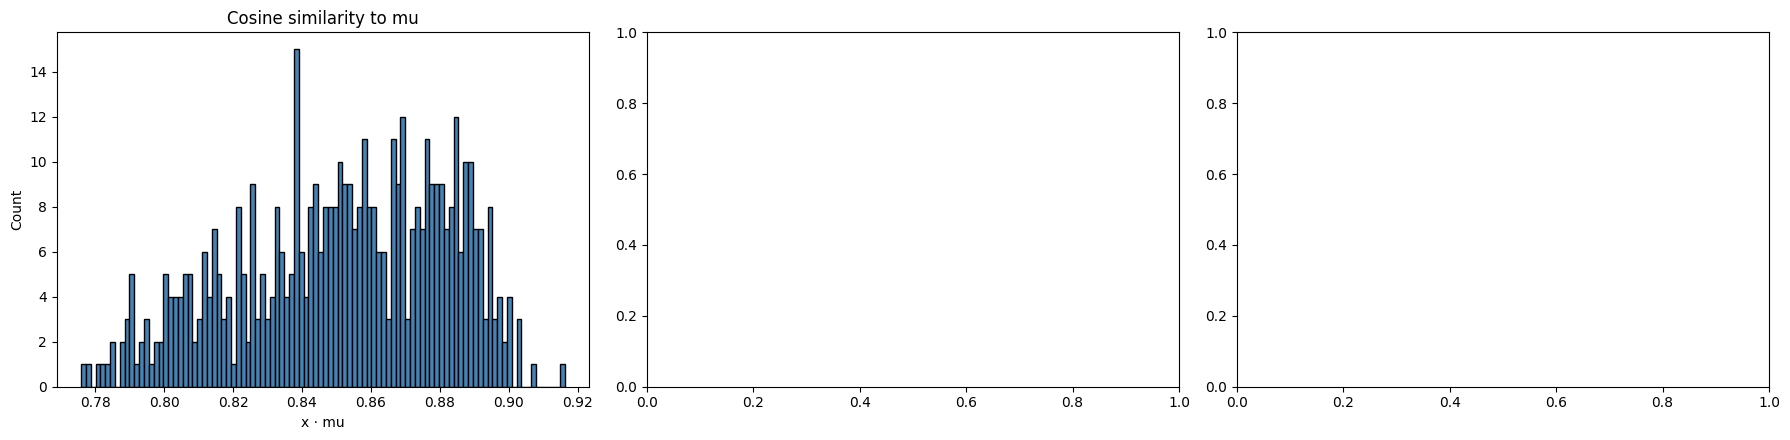

In [26]:
def generate_multi_modal_samples(n_features: int, n_modes: int, samples_per_mode: int=100) -> np.ndarray:
    """Generates samples from a multiple spherical Cauchy distributions."""
    # Initialize the generator
    rng = np.random.default_rng()
    
    samples: list[np.ndarray] = list()
    for i in range(n_modes):
        mu: np.ndarray = rng.random(size=n_features)
        mu: np.ndarray = mu / np.linalg.norm(mu)
        
        mode_samples: np.ndarray = smix.distributions.sample_spherical_cauchy(
            n_samples=100,
            mu=mu,
            rho=0.90,
        )

        samples.append(mode_samples)

    return np.concatenate(samples, axis=0)


# Create random number generator
rng = np.random.default_rng()

    
N_FEATURES: int = 20

X: np.ndarray = generate_multi_modal_samples(
    n_features=N_FEATURES,
    n_modes=5,
)

logger.info(f"Samples: {X.shape}")
logger.info(f"All X unit norm: {np.allclose(np.linalg.norm(X, axis=1), 1.0)}")

mu: np.ndarray = np.ones(N_FEATURES)
mu: np.ndarray = mu / np.linalg.norm(mu)

cosine: np.ndarray = X @ mu

logger.info(cosine)

# ---------------------------
# Visualization
# ---------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

axes[0].hist(cosine, bins=100, color="steelblue", edgecolor="black")
axes[0].set_title("Cosine similarity to mu")
axes[0].set_xlabel("x · mu")
axes[0].set_ylabel("Count")

plt.tight_layout()
plt.show()